Saving Electricity.csv to Electricity.csv
Dataset Shape: (46008, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 46008 entries, 2019-01-01 00:00:00 to 2024-03-31 23:00:00
Freq: h
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Consumption    46008 non-null  float64
 1   Production     46008 non-null  float64
 2   Nuclear        46008 non-null  float64
 3   Wind           46008 non-null  float64
 4   Hydroelectric  46008 non-null  float64
 5   Oil and Gas    46008 non-null  float64
 6   Coal           46008 non-null  float64
 7   Solar          46008 non-null  float64
 8   Biomass        46008 non-null  float64
dtypes: float64(9)
memory usage: 3.5 MB
None

Statistical Summary:
        Consumption    Production       Nuclear          Wind  Hydroelectric  \
count  46008.000000  46008.000000  46008.000000  46008.000000   46008.000000   
mean    6587.755184   6518.806860   1291.171753 

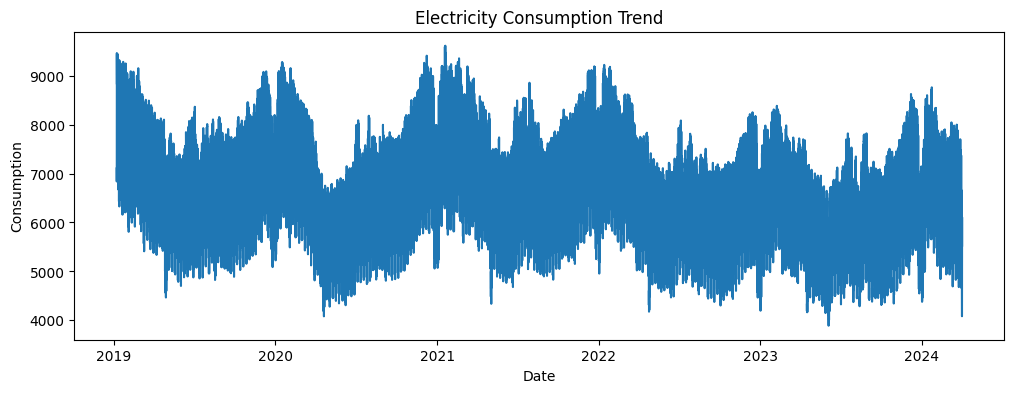

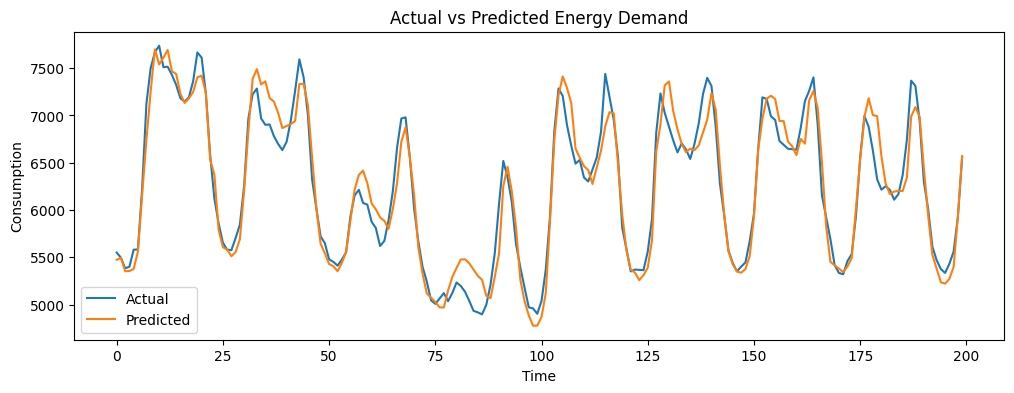

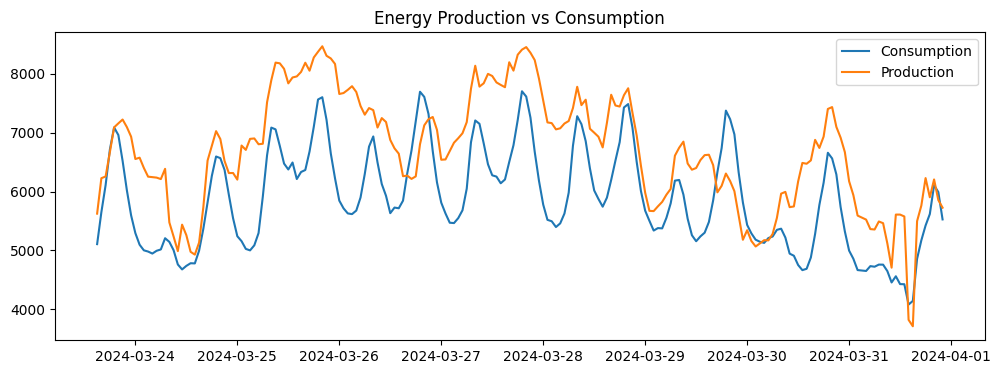

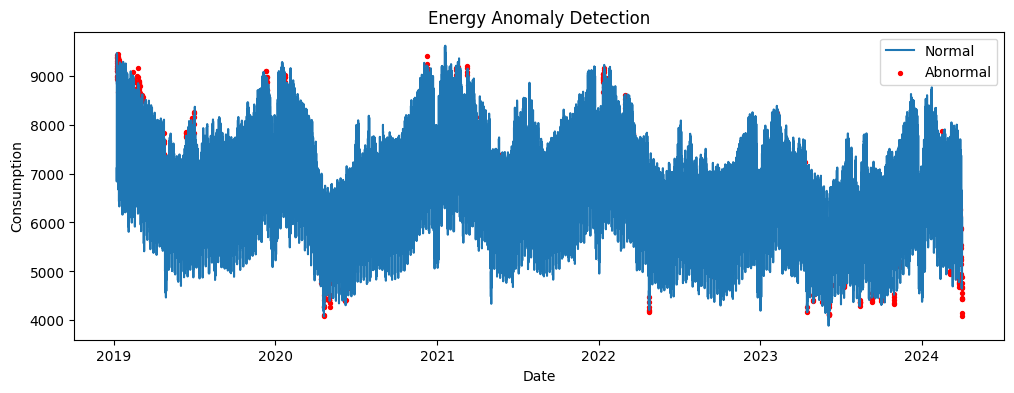

In [1]:

# SMARTGRID AI - ENERGY DEMAND PREDICTION

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 2. UPLOAD AND LOAD DATASET

uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

# 3. DATA CLEANING

df["DateTime"] = pd.to_datetime(df["DateTime"])

df = df.drop_duplicates(subset="DateTime")
df = df.set_index("DateTime").sort_index()

df = df.resample("h").mean()
df = df.interpolate(method="time")

# 4. EXPLORATORY DATA ANALYSIS

print("Dataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

# 5. FEATURE ENGINEERING

df["lag_1"] = df["Consumption"].shift(1)
df["lag_24"] = df["Consumption"].shift(24)
df["lag_168"] = df["Consumption"].shift(168)

df["rolling_mean"] = (
    df["Consumption"].shift(1).rolling(24).mean()
)

df["hour"] = df.index.hour
df["day"] = df.index.dayofweek

df["target"] = df["Consumption"].shift(-1)

df = df.dropna()

# 6. MACHINE LEARNING - DEMAND PREDICTION

features = [
    "lag_1", "lag_24", "lag_168",
    "rolling_mean", "hour", "day"
]

X = df[features]
y = df["target"]

split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

# 7. MODEL EVALUATION

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

baseline_mae = mean_absolute_error(
    y_test, X_test["lag_1"]
)

# 8. ANOMALY DETECTION

anomaly_features = [
    "Consumption", "Production",
    "Wind", "Solar", "Coal"
]

anomaly_model = IsolationForest(
    contamination=0.01,
    random_state=42
)

df["Anomaly"] = anomaly_model.fit_predict(
    df[anomaly_features]
)

df["Anomaly"] = df["Anomaly"].map({
    1: "Normal",
    -1: "Abnormal"
})

# 9. FINAL RESULTS

print("\n========== SMARTGRID AI RESULTS ==========")

print("\nENERGY DEMAND PREDICTION")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("Previous-hour Baseline MAE:", round(baseline_mae, 2))

print("\nNEXT HOUR PREDICTION")
print(round(model.predict(X.iloc[[-1]])[0], 2))

print("\nANOMALY DETECTION")
print(df["Anomaly"].value_counts())

print("\n==========================================")

# 10. VISUALIZATION

# Electricity Consumption

plt.figure(figsize=(12, 4))
plt.plot(df["Consumption"])
plt.title("Electricity Consumption Trend")
plt.xlabel("Date")
plt.ylabel("Consumption")
plt.show()

# Actual vs Predicted

plt.figure(figsize=(12, 4))
plt.plot(y_test.iloc[:200].values, label="Actual")
plt.plot(predictions[:200], label="Predicted")
plt.title("Actual vs Predicted Energy Demand")
plt.xlabel("Time")
plt.ylabel("Consumption")
plt.legend()
plt.show()

# Energy Production vs Consumption

plt.figure(figsize=(12, 4))
plt.plot(df["Consumption"].iloc[-200:], label="Consumption")
plt.plot(df["Production"].iloc[-200:], label="Production")
plt.title("Energy Production vs Consumption")
plt.legend()
plt.show()

# Anomaly Detection

plt.figure(figsize=(12, 4))

normal = df[df["Anomaly"] == "Normal"]
abnormal = df[df["Anomaly"] == "Abnormal"]

plt.plot(
    normal.index,
    normal["Consumption"],
    label="Normal"
)

plt.scatter(
    abnormal.index,
    abnormal["Consumption"],
    color="red",
    label="Abnormal",
    s=8
)

plt.title("Energy Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Consumption")
plt.legend()
plt.show()

# END OF SMARTGRID AI
